<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS13_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Jumlah data training:", X_train.shape)
print("Jumlah data testing:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Jumlah data training: (60000, 28, 28)
Jumlah data testing: (10000, 28, 28)


In [3]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Nilai minimum:", X_train.min())
print("Nilai maksimum:", X_train.max())

Nilai minimum: 0.0
Nilai maksimum: 1.0


In [4]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("Bentuk label training:", y_train.shape)
print("Bentuk label testing:", y_test.shape)

Bentuk label training: (60000, 10)
Bentuk label testing: (10000, 10)


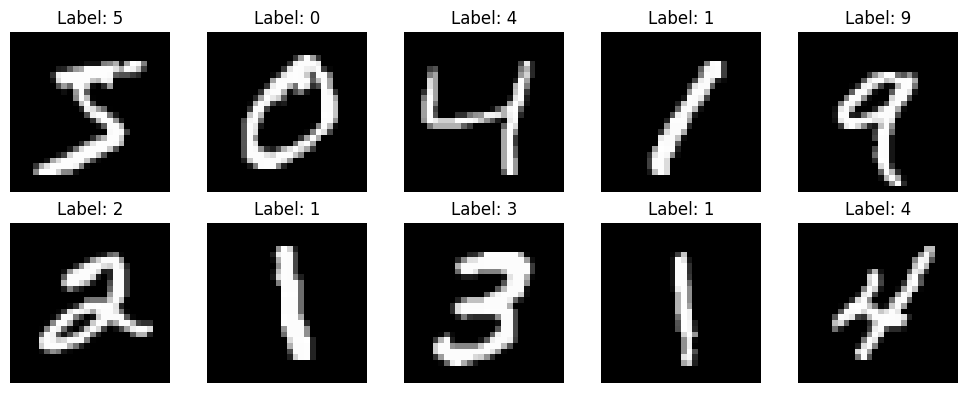

In [5]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title("Label: " + str(np.argmax(y_train[i])))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

training_time = time.time() - start_time

print("Waktu pelatihan:", round(training_time, 2), "detik")

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9201 - loss: 0.2692 - val_accuracy: 0.9505 - val_loss: 0.1678
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9639 - loss: 0.1163 - val_accuracy: 0.9655 - val_loss: 0.1161
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9746 - loss: 0.0809 - val_accuracy: 0.9694 - val_loss: 0.1012
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9814 - loss: 0.0601 - val_accuracy: 0.9702 - val_loss: 0.1067
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9845 - loss: 0.0479 - val_accuracy: 0.9720 - val_loss: 0.0969
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9880 - loss: 0.0377 - val_accuracy: 0.9728 - val_loss: 0.0959
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9902 - loss: 0.0306 - val_accuracy: 0.9748 - val_loss: 0.0972
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9914 - loss: 0.0247 

In [9]:
loss, acc = model.evaluate(X_test, y_test)

print(f"Loss pada data uji: {loss:.4f}")
print(f"Akurasi pada data uji: {acc:.4f}")
print(f"Akurasi dalam persen: {acc*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9778 - loss: 0.0897
Loss pada data uji: 0.0897
Akurasi pada data uji: 0.9778
Akurasi dalam persen: 97.78%


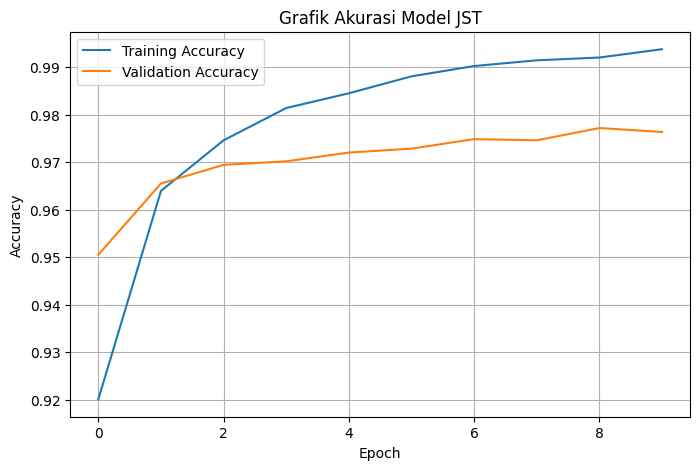

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Grafik Akurasi Model JST')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

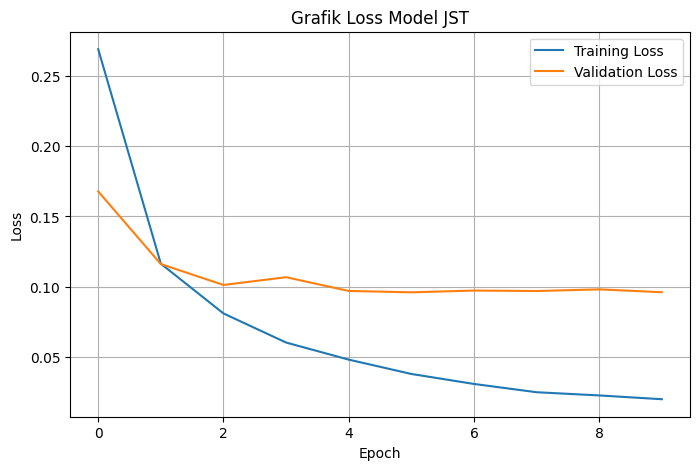

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Grafik Loss Model JST')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

**EKSPERIMEN 1**

In [12]:
model_2 = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(256, activation='relu'),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

model_2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [13]:
start_time = time.time()

history_2 = model_2.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

time_2 = time.time() - start_time

print("Waktu pelatihan model 2:", round(time_2, 2), "detik")

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9316 - loss: 0.2306 - val_accuracy: 0.9644 - val_loss: 0.1172
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9709 - loss: 0.0946 - val_accuracy: 0.9684 - val_loss: 0.1066
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9810 - loss: 0.0612 - val_accuracy: 0.9758 - val_loss: 0.0874
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9845 - loss: 0.0475 - val_accuracy: 0.9753 - val_loss: 0.0842
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9881 - loss: 0.0365 - val_accuracy: 0.9733 - val_loss: 0.0962
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9904 - loss: 0.0297 - val_accuracy: 0.9768 - val_loss: 0.0929
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9917 - loss: 0.0250 - val_accuracy: 0.9703 - val_loss: 0.1257
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9928 - loss: 0

In [14]:
loss_2, acc_2 = model_2.evaluate(X_test, y_test)

print(f"Akurasi model 2: {acc_2*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9794 - loss: 0.1067
Akurasi model 2: 97.94%


**EKSPERIMEN 2**

In [15]:
model_3 = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(256, activation='relu'),

    Dense(128, activation='relu'),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

model_3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [16]:
start_time = time.time()

history_3 = model_3.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

time_3 = time.time() - start_time

print("Waktu pelatihan model 3:", round(time_3, 2), "detik")

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9287 - loss: 0.2373 - val_accuracy: 0.9607 - val_loss: 0.1283
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9696 - loss: 0.0988 - val_accuracy: 0.9706 - val_loss: 0.0985
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9789 - loss: 0.0692 - val_accuracy: 0.9742 - val_loss: 0.0860
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9838 - loss: 0.0518 - val_accuracy: 0.9725 - val_loss: 0.0977
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9860 - loss: 0.0434 - val_accuracy: 0.9755 - val_loss: 0.0957
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9880 - loss: 0.0372 - val_accuracy: 0.9771 - val_loss: 0.0869
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9900 - loss: 0.0301 - val_accuracy: 0.9766 - val_loss: 0.0918
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - accuracy: 0.9920 - loss: 0

In [17]:
loss_3, acc_3 = model_3.evaluate(X_test, y_test)

print(f"Akurasi model 3: {acc_3*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9804 - loss: 0.0831
Akurasi model 3: 98.04%


**EKSPERIMEN 3**

In [18]:
model_4 = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='sigmoid'),

    Dense(64, activation='sigmoid'),

    Dense(10, activation='softmax')
])

model_4.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [19]:
start_time = time.time()

history_4 = model_4.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

time_4 = time.time() - start_time

print("Waktu pelatihan Sigmoid:", round(time_4, 2), "detik")

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8668 - loss: 0.5296 - val_accuracy: 0.9339 - val_loss: 0.2331
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9407 - loss: 0.2025 - val_accuracy: 0.9493 - val_loss: 0.1732
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9570 - loss: 0.1444 - val_accuracy: 0.9618 - val_loss: 0.1310
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9680 - loss: 0.1084 - val_accuracy: 0.9669 - val_loss: 0.1144
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9753 - loss: 0.0840 - val_accuracy: 0.9691 - val_loss: 0.1067
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9809 - loss: 0.0663 - val_accuracy: 0.9703 - val_loss: 0.0977
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9845 - loss: 0.0536 - val_accuracy: 0.9725 - val_loss: 0.0954
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9885 - loss: 0.0430 -

In [20]:
loss_4, acc_4 = model_4.evaluate(X_test, y_test)

print(f"Akurasi Sigmoid: {acc_4*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9732 - loss: 0.0872
Akurasi Sigmoid: 97.32%


**PERBANDINGAN EKSPERIMEN**

In [21]:
import pandas as pd

hasil = {
    'Model': [
        '2 Hidden Layer (128, 64)',
        '2 Hidden Layer (256, 128)',
        '3 Hidden Layer (256, 128, 64)',
        '2 Hidden Layer Sigmoid'
    ],

    'Akurasi (%)': [
        acc * 100,
        acc_2 * 100,
        acc_3 * 100,
        acc_4 * 100
    ],

    'Waktu Training (detik)': [
        training_time,
        time_2,
        time_3,
        time_4
    ]
}

tabel = pd.DataFrame(hasil)

print(tabel.to_string(index=False))

                        Model  Akurasi (%)  Waktu Training (detik)
     2 Hidden Layer (128, 64)    97.780001               86.767286
    2 Hidden Layer (256, 128)    97.939998              110.773411
3 Hidden Layer (256, 128, 64)    98.040003              121.232224
       2 Hidden Layer Sigmoid    97.320002               87.543737


In [22]:
model_terbaik = tabel.loc[tabel['Akurasi (%)'].idxmax()]

print("Model dengan akurasi tertinggi:")
print(model_terbaik)

Model dengan akurasi tertinggi:
Model                     3 Hidden Layer (256, 128, 64)
Akurasi (%)                                   98.040003
Waktu Training (detik)                       121.232224
Name: 2, dtype: object


**MENGUJI PREDIKSI ANGKA TULISAN TANGAN**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


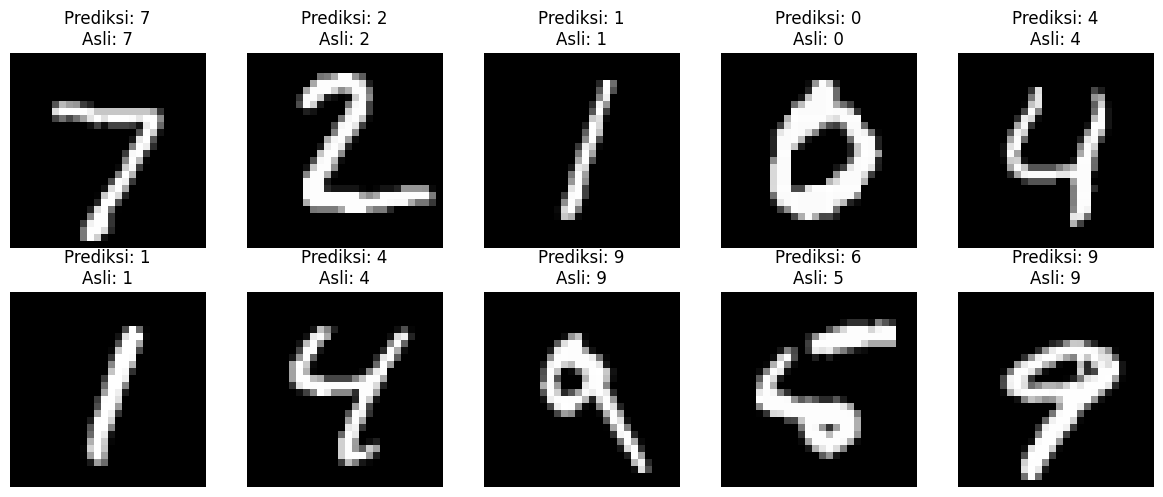

In [23]:
prediksi = model.predict(X_test[:10])

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i], cmap='gray')

    hasil_prediksi = np.argmax(prediksi[i])
    label_asli = np.argmax(y_test[i])

    plt.title(
        f"Prediksi: {hasil_prediksi}\nAsli: {label_asli}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()